In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Check karna ki GPU on hai ya nahi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dimag (Device) set to: {device}\n")

# 2. Generator (Artist AI) ka Architecture Banana
class Generator(nn.Module):
    def __init__(self, noise_dim):
        super(Generator, self).__init__()
        
        # Ye AI random numbers (noise) ko dheere-dheere ek photo me badlega
        self.model = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2),
            
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.2),
            
            # Aakhiri layer: Ise 64x64 pixels ki RGB (3 channel) photo banani hai
            nn.Linear(1024, 3 * 64 * 64), 
            nn.Tanh()
        )
        
    def forward(self, x):
        output = self.model(x)
        output = output.view(-1, 3, 64, 64) 
        return output

# 3. Model ko zinda karna aur GPU par bhejna
noise_dim = 100 
my_artist = Generator(noise_dim).to(device)

print("✅ Artist AI (Generator) tayar ho gaya hai!")

# 4. Artist ka chota sa Test (ERROR FIXED)
my_artist.eval() # YAHAN BADLAV HAI: AI ko test mode me dala
with torch.no_grad():
    random_inspiration = torch.randn(1, noise_dim).to(device) # 100 random numbers
    nakli_photo = my_artist(random_inspiration)

print(f"Artist ne ek nakli photo banayi jiska size hai: {nakli_photo.shape}")

Dimag (Device) set to: cuda

✅ Artist AI (Generator) tayar ho gaya hai!
Artist ne ek nakli photo banayi jiska size hai: torch.Size([1, 3, 64, 64])


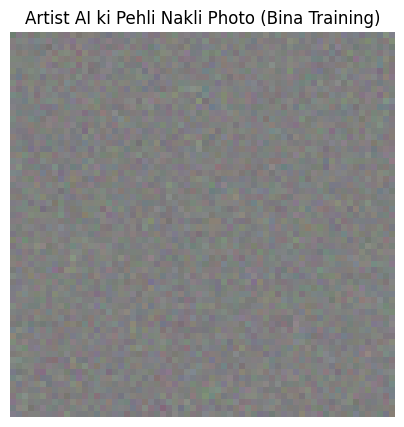

In [3]:
import matplotlib.pyplot as plt

# 1. GPU se CPU me lana aur aage ka extra '1' (batch size) hatana
image_to_show = nakli_photo.detach().cpu().squeeze(0)

# 2. PyTorch [C, H, W] ko Matplotlib [H, W, C] me ghumana
image_to_show = image_to_show.permute(1, 2, 0)

# 3. Tanh ke -1 se 1 wale colors ko normalize karke 0 se 1 ke beech lana
image_to_show = (image_to_show + 1) / 2 

# Screen par dikhana
plt.figure(figsize=(5, 5))
plt.imshow(image_to_show.numpy())
plt.title("Artist AI ki Pehli Nakli Photo (Bina Training)")
plt.axis("off")
plt.show()

In [5]:
# 5. Police AI (Discriminator) ka Architecture Banana
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        
        # Ye AI photo (3x64x64) ko dekh kar batayega ki wo Asli hai (1) ya Nakli (0)
        self.model = nn.Sequential(
            nn.Linear(3 * 64 * 64, 512),
            nn.LeakyReLU(0.2),
            
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            
            nn.Linear(256, 1),
            nn.Sigmoid() # Sigmoid hamesha aakhiri score ko 0 aur 1 ke beech me rakhta hai
        )
        
    def forward(self, x):
        # Photo (Grid) ko wapas ek lambi line (1D) me kholna taaki AI use padh sake
        x = x.view(x.size(0), -1) 
        output = self.model(x)
        return output

# 6. Police AI ko zinda karna aur GPU par bhejna
my_police = Discriminator().to(device)
print("🚓 Police AI (Discriminator) tayar ho gaya hai!\n")

# 7. Police ka Test: Us nakli kachre wali photo par Police ki checking
my_police.eval()
with torch.no_grad():
    # Police nakli photo ko check kar rahi hai
    police_ka_faisla = my_police(nakli_photo)

print(f"Police ne is Nakli Photo ko kya score diya? (0 = Fake, 1 = Real): {police_ka_faisla.item():.4f}")

🚓 Police AI (Discriminator) tayar ho gaya hai!

Police ne is Nakli Photo ko kya score diya? (0 = Fake, 1 = Real): 0.4956


In [8]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# 1. Smart Path Finder: Ye khud photos wala sahi folder dhoondhega
kaggle_input_path = '/kaggle/input'
images_dir = None

for root, dirs, files in os.walk(kaggle_input_path):
    for file in files:
        # Jaha pehli .jpg photo milegi, wahi hamara folder hoga
        if file.lower().endswith('.jpg'): 
            images_dir = root 
            break
    if images_dir:
        break

if images_dir is None:
    print("❌ Error: Photos nahi mil rahi hain. Kya aapne right side se Flickr dataset add kiya hai?")
else:
    print(f"✅ Smart Finder ne sahi rasta dhoondh liya: {images_dir}\n")

    # 2. GAN ke liye Data Loader (Sirf photos, no text)
    class AsliPhotosDataset(Dataset):
        def __init__(self, img_dir, transform=None):
            self.img_dir = img_dir
            # Folder se sirf .jpg files nikalna, aur fast training ke liye shuru ki 5000 photos lena
            all_images = [f for f in os.listdir(img_dir) if f.lower().endswith('.jpg')]
            self.img_names = all_images[:5000] 
            self.transform = transform

        def __len__(self):
            return len(self.img_names)

        def __getitem__(self, idx):
            img_path = os.path.join(self.img_dir, self.img_names[idx])
            image = Image.open(img_path).convert("RGB")
            if self.transform:
                image = self.transform(image)
            return image

    # 3. Photos ko 64x64 karna aur colors ko -1 se 1 ke beech lana
    gan_transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) 
    ])

    print("📸 Asli Photos load ho rahi hain...\n")

    # 4. Dataset aur Batch system banana
    real_dataset = AsliPhotosDataset(images_dir, transform=gan_transform)
    real_dataloader = DataLoader(real_dataset, batch_size=64, shuffle=True) 

    print(f"🎉 Total {len(real_dataset)} Asli photos GAN ki training ke liye load ho gayi!")

✅ Smart Finder ne sahi rasta dhoondh liya: /kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/Images

📸 Asli Photos load ho rahi hain...

🎉 Total 5000 Asli photos GAN ki training ke liye load ho gayi!


In [9]:
import torch.optim as optim
import torch.nn as nn

# 1. Loss function aur Optimizers (Dono AI ke dimag ko theek karne ke liye)
criterion = nn.BCELoss() # Binary Cross Entropy - Ye batayega ki Police kitni dur hai Asli(1) ya Nakli(0) samajhne se
optimizer_generator = optim.Adam(my_artist.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_discriminator = optim.Adam(my_police.parameters(), lr=0.0002, betas=(0.5, 0.999))

# 2. Training Loop (Dono ka aapas me Yuddh)
epochs = 5 # Abhi ke liye sirf 5 rounds (Training fast karne ke liye)
print("⚔️ Artist vs Police ki Training Shuru (Yuddh Start)!\n")

for epoch in range(epochs):
    # Har epoch ke liye loss ko zero se shuru karein
    gen_loss_total = 0
    disc_loss_total = 0
    
    for i, real_images in enumerate(real_dataloader):
        batch_size = real_images.size(0)
        
        # Real images ko GPU par bhejenge
        real_images = real_images.to(device)
        
        # Asli photos ko 1 aur Nakli ko 0 ka label dena
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # -----------------------------------------------------
        # 1. Police (Discriminator) ki Training
        # -----------------------------------------------------
        optimizer_discriminator.zero_grad()
        
        # Police Asli photo check karegi
        outputs_real = my_police(real_images)
        loss_real = criterion(outputs_real, real_labels)
        
        # Artist se nakli photo banwayenge aur Police ko dikhayenge
        noise = torch.randn(batch_size, noise_dim).to(device)
        fake_images = my_artist(noise)
        
        outputs_fake = my_police(fake_images.detach()) # Artist ko update nahi karna
        loss_fake = criterion(outputs_fake, fake_labels)
        
        # Dono losses ko jodkar Police ko sikhana
        loss_disc = loss_real + loss_fake
        loss_disc.backward()
        optimizer_discriminator.step()
        
        # -----------------------------------------------------
        # 2. Artist (Generator) ki Training
        # -----------------------------------------------------
        optimizer_generator.zero_grad()
        
        # Artist apni banayi nakli photo se Police ko bewakoof banayega (Asli label dekar)
        outputs = my_police(fake_images)
        loss_gen = criterion(outputs, real_labels) # Artist chahta hai ki Police isse Asli(1) samjhe
        
        # Artist ko sikhana
        loss_gen.backward()
        optimizer_generator.step()

        # Loss record karna
        gen_loss_total += loss_gen.item()
        disc_loss_total += loss_disc.item()
        
    print(f"⭐ Epoch [{epoch+1}/{epochs}] Pura Hua | Police Loss: {disc_loss_total/len(real_dataloader):.4f} | Artist Loss: {gen_loss_total/len(real_dataloader):.4f}")

print("\n🎉 Training Complete! Artist ab nakli photo banakar Police ko dokha de sakta hai!")

⚔️ Artist vs Police ki Training Shuru (Yuddh Start)!

⭐ Epoch [1/5] Pura Hua | Police Loss: 0.7803 | Artist Loss: 0.8154
⭐ Epoch [2/5] Pura Hua | Police Loss: 0.7572 | Artist Loss: 0.8698
⭐ Epoch [3/5] Pura Hua | Police Loss: 0.7212 | Artist Loss: 1.0006
⭐ Epoch [4/5] Pura Hua | Police Loss: 0.8141 | Artist Loss: 1.0322
⭐ Epoch [5/5] Pura Hua | Police Loss: 0.8941 | Artist Loss: 1.0611

🎉 Training Complete! Artist ab nakli photo banakar Police ko dokha de sakta hai!


🎨 Trained Artist ki nayi photo generate ho rahi hai...



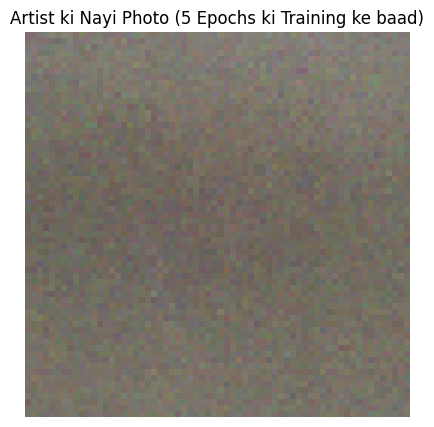

In [10]:
import matplotlib.pyplot as plt

print("🎨 Trained Artist ki nayi photo generate ho rahi hai...\n")

# 1. Artist ko wapas Test Mode me daalna
my_artist.eval()
with torch.no_grad():
    # Naya 100-dimension ka noise (inspiration)
    nayi_inspiration = torch.randn(1, noise_dim).to(device)
    # Trained Artist se photo banwana
    trained_nakli_photo = my_artist(nayi_inspiration)

# 2. PyTorch Tensor ko Matplotlib Image me badalna
image_to_show = trained_nakli_photo.detach().cpu().squeeze(0)
image_to_show = image_to_show.permute(1, 2, 0)
image_to_show = (image_to_show + 1) / 2 # Normalize colors to 0-1

# 3. Screen par dikhana
plt.figure(figsize=(5, 5))
plt.imshow(image_to_show.numpy())
plt.title("Artist ki Nayi Photo (5 Epochs ki Training ke baad)")
plt.axis("off")
plt.show()

In [11]:
import torch.nn as nn
import torch

# 1. Naya Pro Artist (DCGAN Generator) Architecture
class DCGAN_Generator(nn.Module):
    def __init__(self, noise_dim):
        super(DCGAN_Generator, self).__init__()
        
        # Ye naya AI noise ko chote 2D blocks me badlega aur unhe bada karta jayega
        self.model = nn.Sequential(
            # Input: 100 dimension ka noise. Output: 4x4 size ka block (512 channels)
            nn.ConvTranspose2d(noise_dim, 512, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            
            # 4x4 ko double karke 8x8 banayega (256 channels)
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            
            # 8x8 ko double karke 16x16 banayega (128 channels)
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            
            # 16x16 ko double karke 32x32 banayega (64 channels)
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            
            # 32x32 ko double karke final 64x64 RGB (3 channels) photo banayega
            nn.ConvTranspose2d(64, 3, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh() # Colors ko -1 se 1 me set karne ke liye
        )

    def forward(self, x):
        # Noise ko 2D image format me badalna zaroori hai (Batch, Channels, Height, Width)
        x = x.view(x.size(0), x.size(1), 1, 1)
        return self.model(x)

# 2. Naye Pro Artist ko zinda karna aur GPU par bhejna
my_pro_artist = DCGAN_Generator(noise_dim).to(device)

print("🚀 Naya 'DCGAN Pro Artist' tayar hai!")

# 3. Test: Naye Artist se pehli nakli photo banwana
my_pro_artist.eval()
with torch.no_grad():
    random_inspiration = torch.randn(1, noise_dim).to(device)
    nayi_photo = my_pro_artist(random_inspiration)

print(f"Pro Artist ne photo banayi jiska size hai: {nayi_photo.shape}")

🚀 Naya 'DCGAN Pro Artist' tayar hai!
Pro Artist ne photo banayi jiska size hai: torch.Size([1, 3, 64, 64])


In [12]:
# 4. Naya Pro Police (DCGAN Discriminator) Architecture
class DCGAN_Discriminator(nn.Module):
    def __init__(self):
        super(DCGAN_Discriminator, self).__init__()
        
        # Ye AI 64x64 photo ko scan karke ek single score (0 ya 1) me badlega
        self.model = nn.Sequential(
            # Input: 3 x 64 x 64. Output: 64 x 32 x 32 (Aadha size)
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 32x32 ko aadha karke 16x16 banayega
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 16x16 ko aadha karke 8x8 banayega
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 8x8 ko aadha karke 4x4 banayega
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 4x4 block ko ek single number (0 ya 1) me badalna
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=False),
            nn.Sigmoid() # Score ko 0 aur 1 ke beech lock karna
        )

    def forward(self, x):
        output = self.model(x)
        # Output abhi [Batch, 1, 1, 1] shape me hai, isko flat karke [Batch, 1] me lana hai
        return output.view(-1, 1)

# 5. Nayi Pro Police ko zinda karna aur GPU par bhejna
my_pro_police = DCGAN_Discriminator().to(device)

print("🚓 Nayi 'DCGAN Pro Police' bhi tayar hai!")

# 6. Test: Nayi Police se nayi nakli photo check karwana
my_pro_police.eval()
with torch.no_grad():
    police_ka_faisla = my_pro_police(nayi_photo)

print(f"Pro Police ne is nayi photo ko score diya: {police_ka_faisla.item():.4f}")

🚓 Nayi 'DCGAN Pro Police' bhi tayar hai!
Pro Police ne is nayi photo ko score diya: 0.5000


In [13]:
import torch.optim as optim
import torch.nn as nn

# 1. Naye Pro Models ke liye naye Optimizers
criterion = nn.BCELoss()
# DHYAN DEIN: Yahan hum apne naye 'my_pro_artist' aur 'my_pro_police' use kar rahe hain
optimizer_pro_generator = optim.Adam(my_pro_artist.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_pro_discriminator = optim.Adam(my_pro_police.parameters(), lr=0.0002, betas=(0.5, 0.999))

# 2. DCGAN Maha-Yuddh (Training Loop)
epochs = 10 # 10 rounds taaki achi shapes ban sakein
print("⚔️ DCGAN Pro Artist vs Pro Police ki Training Shuru!\n")

for epoch in range(epochs):
    gen_loss_total = 0
    disc_loss_total = 0
    
    for i, real_images in enumerate(real_dataloader):
        batch_size = real_images.size(0)
        real_images = real_images.to(device)
        
        # Labels
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # -----------------------------------------------------
        # 1. Pro Police (Discriminator) ki Training
        # -----------------------------------------------------
        optimizer_pro_discriminator.zero_grad()
        
        # Police asli photo check karegi
        outputs_real = my_pro_police(real_images)
        loss_real = criterion(outputs_real, real_labels)
        
        # Artist se naya noise dekar nakli photo banwana
        noise = torch.randn(batch_size, noise_dim).to(device)
        fake_images = my_pro_artist(noise)
        
        # Police nakli photo check karegi
        outputs_fake = my_pro_police(fake_images.detach())
        loss_fake = criterion(outputs_fake, fake_labels)
        
        # Police ka total loss aur update
        loss_disc = loss_real + loss_fake
        loss_disc.backward()
        optimizer_pro_discriminator.step()
        
        # -----------------------------------------------------
        # 2. Pro Artist (Generator) ki Training
        # -----------------------------------------------------
        optimizer_pro_generator.zero_grad()
        
        # Artist chahta hai ki uski nakli photo ko Police Asli (1) bole
        outputs = my_pro_police(fake_images)
        loss_gen = criterion(outputs, real_labels) 
        
        # Artist ka update
        loss_gen.backward()
        optimizer_pro_generator.step()

        gen_loss_total += loss_gen.item()
        disc_loss_total += loss_disc.item()
        
    print(f"⭐ Epoch [{epoch+1}/{epochs}] Pura Hua | Police Loss: {disc_loss_total/len(real_dataloader):.4f} | Artist Loss: {gen_loss_total/len(real_dataloader):.4f}")

print("\n🎉 DCGAN Training Complete! Ab dekhte hain asli kamaal!")

⚔️ DCGAN Pro Artist vs Pro Police ki Training Shuru!

⭐ Epoch [1/10] Pura Hua | Police Loss: 0.3404 | Artist Loss: 4.4764
⭐ Epoch [2/10] Pura Hua | Police Loss: 0.5660 | Artist Loss: 2.6849
⭐ Epoch [3/10] Pura Hua | Police Loss: 0.2548 | Artist Loss: 4.0771
⭐ Epoch [4/10] Pura Hua | Police Loss: 0.1527 | Artist Loss: 4.1185
⭐ Epoch [5/10] Pura Hua | Police Loss: 0.2231 | Artist Loss: 4.4135
⭐ Epoch [6/10] Pura Hua | Police Loss: 0.1794 | Artist Loss: 4.2710
⭐ Epoch [7/10] Pura Hua | Police Loss: 0.1151 | Artist Loss: 5.2466
⭐ Epoch [8/10] Pura Hua | Police Loss: 0.0983 | Artist Loss: 4.5657
⭐ Epoch [9/10] Pura Hua | Police Loss: 0.4397 | Artist Loss: 5.3407
⭐ Epoch [10/10] Pura Hua | Police Loss: 0.1749 | Artist Loss: 3.8178

🎉 DCGAN Training Complete! Ab dekhte hain asli kamaal!


🎨 DCGAN Pro Artist ki nayi photo (10 Epochs ke baad)...



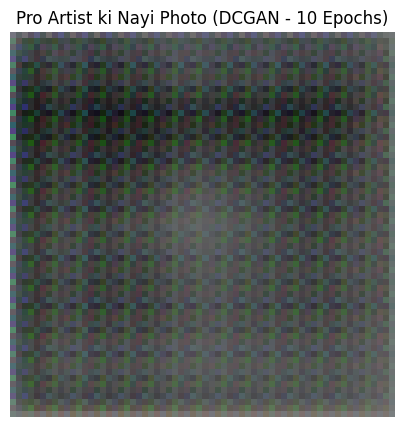

In [14]:
import matplotlib.pyplot as plt

print("🎨 DCGAN Pro Artist ki nayi photo (10 Epochs ke baad)...\n")

# 1. Pro Artist ko wapas Test Mode me daalna
my_pro_artist.eval()
with torch.no_grad():
    # Naya 100-dimension ka noise
    nayi_inspiration = torch.randn(1, noise_dim).to(device)
    # Pro Artist se final photo banwana
    trained_nakli_photo = my_pro_artist(nayi_inspiration)

# 2. PyTorch Tensor ko Matplotlib Image me badalna
image_to_show = trained_nakli_photo.detach().cpu().squeeze(0)
image_to_show = image_to_show.permute(1, 2, 0)
image_to_show = (image_to_show + 1) / 2 # Normalize colors to 0-1

# 3. Screen par dikhana
plt.figure(figsize=(5, 5))
plt.imshow(image_to_show.numpy())
plt.title("Pro Artist ki Nayi Photo (DCGAN - 10 Epochs)")
plt.axis("off")
plt.show()

🔥 Asli Yuddh Shuru! 100 Epochs ki training (Save feature ke sath)...

⭐ Epoch [1/100] | Police Loss: 0.1073 | Artist Loss: 3.9742
⭐ Epoch [2/100] | Police Loss: 0.2159 | Artist Loss: 5.7043
⭐ Epoch [3/100] | Police Loss: 0.1733 | Artist Loss: 3.7993
⭐ Epoch [4/100] | Police Loss: 0.1323 | Artist Loss: 3.8605
⭐ Epoch [5/100] | Police Loss: 0.5320 | Artist Loss: 5.5448
⭐ Epoch [6/100] | Police Loss: 0.9933 | Artist Loss: 4.9825
⭐ Epoch [7/100] | Police Loss: 0.1766 | Artist Loss: 4.2973
⭐ Epoch [8/100] | Police Loss: 0.6625 | Artist Loss: 4.5735
⭐ Epoch [9/100] | Police Loss: 0.7344 | Artist Loss: 3.1964
⭐ Epoch [10/100] | Police Loss: 0.6868 | Artist Loss: 2.7860
💾 Epoch 10 par Artist aur Police ka dimag save ho raha hai...


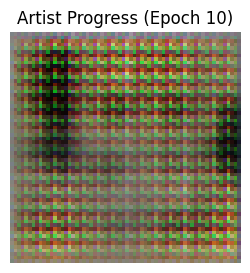

⭐ Epoch [11/100] | Police Loss: 13.3407 | Artist Loss: 1.7586
⭐ Epoch [12/100] | Police Loss: 1.1022 | Artist Loss: 1.5648
⭐ Epoch [14/100] | Police Loss: 1.1120 | Artist Loss: 1.6430
⭐ Epoch [15/100] | Police Loss: 1.0730 | Artist Loss: 1.4961
⭐ Epoch [16/100] | Police Loss: 1.0711 | Artist Loss: 1.7673
⭐ Epoch [17/100] | Police Loss: 1.0803 | Artist Loss: 1.7153
⭐ Epoch [18/100] | Police Loss: 1.0373 | Artist Loss: 2.0170
⭐ Epoch [19/100] | Police Loss: 0.8901 | Artist Loss: 2.0827
⭐ Epoch [20/100] | Police Loss: 0.9668 | Artist Loss: 2.3453
💾 Epoch 20 par Artist aur Police ka dimag save ho raha hai...


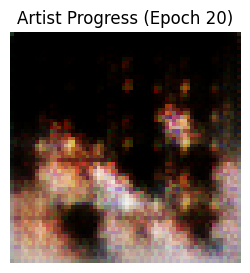

⭐ Epoch [21/100] | Police Loss: 0.9478 | Artist Loss: 2.2452
⭐ Epoch [22/100] | Police Loss: 0.8918 | Artist Loss: 2.4383
⭐ Epoch [23/100] | Police Loss: 0.7687 | Artist Loss: 2.4018
⭐ Epoch [24/100] | Police Loss: 0.8629 | Artist Loss: 2.6422
⭐ Epoch [25/100] | Police Loss: 0.7694 | Artist Loss: 2.7660
⭐ Epoch [26/100] | Police Loss: 0.7783 | Artist Loss: 2.6821
⭐ Epoch [27/100] | Police Loss: 0.6747 | Artist Loss: 3.2512
⭐ Epoch [28/100] | Police Loss: 0.7409 | Artist Loss: 2.9317
⭐ Epoch [29/100] | Police Loss: 0.7031 | Artist Loss: 2.9394
⭐ Epoch [30/100] | Police Loss: 0.7119 | Artist Loss: 2.9099
💾 Epoch 30 par Artist aur Police ka dimag save ho raha hai...


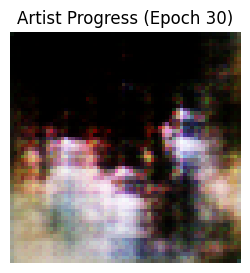

⭐ Epoch [31/100] | Police Loss: 0.7572 | Artist Loss: 3.0208
⭐ Epoch [32/100] | Police Loss: 0.7329 | Artist Loss: 3.0868
⭐ Epoch [33/100] | Police Loss: 0.6027 | Artist Loss: 3.3739
⭐ Epoch [34/100] | Police Loss: 0.6482 | Artist Loss: 3.5146
⭐ Epoch [35/100] | Police Loss: 0.5858 | Artist Loss: 3.5560
⭐ Epoch [36/100] | Police Loss: 0.5924 | Artist Loss: 3.9338
⭐ Epoch [37/100] | Police Loss: 0.5951 | Artist Loss: 3.7561
⭐ Epoch [38/100] | Police Loss: 0.6269 | Artist Loss: 3.4835
⭐ Epoch [39/100] | Police Loss: 0.6682 | Artist Loss: 3.6070
⭐ Epoch [40/100] | Police Loss: 0.5803 | Artist Loss: 3.5113
💾 Epoch 40 par Artist aur Police ka dimag save ho raha hai...


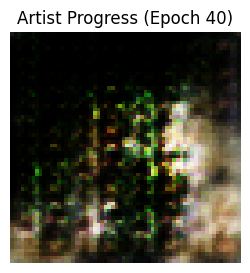

⭐ Epoch [41/100] | Police Loss: 0.5999 | Artist Loss: 3.6187
⭐ Epoch [42/100] | Police Loss: 0.6585 | Artist Loss: 3.3371
⭐ Epoch [43/100] | Police Loss: 0.7142 | Artist Loss: 3.2339
⭐ Epoch [44/100] | Police Loss: 0.6639 | Artist Loss: 3.4071
⭐ Epoch [45/100] | Police Loss: 0.6673 | Artist Loss: 3.1621
⭐ Epoch [46/100] | Police Loss: 1.1514 | Artist Loss: 2.9568
⭐ Epoch [47/100] | Police Loss: 0.6456 | Artist Loss: 2.9450
⭐ Epoch [48/100] | Police Loss: 0.5695 | Artist Loss: 3.1495
⭐ Epoch [49/100] | Police Loss: 0.6310 | Artist Loss: 3.0303
⭐ Epoch [50/100] | Police Loss: 0.5697 | Artist Loss: 3.2787
💾 Epoch 50 par Artist aur Police ka dimag save ho raha hai...


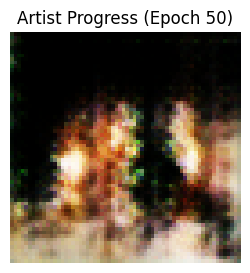

⭐ Epoch [51/100] | Police Loss: 0.6729 | Artist Loss: 3.2848
⭐ Epoch [52/100] | Police Loss: 0.6156 | Artist Loss: 3.1218
⭐ Epoch [53/100] | Police Loss: 0.6868 | Artist Loss: 2.9617
⭐ Epoch [54/100] | Police Loss: 0.6306 | Artist Loss: 2.8896
⭐ Epoch [55/100] | Police Loss: 0.6458 | Artist Loss: 2.7819
⭐ Epoch [56/100] | Police Loss: 0.6878 | Artist Loss: 3.1154
⭐ Epoch [57/100] | Police Loss: 0.5891 | Artist Loss: 3.2239
⭐ Epoch [58/100] | Police Loss: 0.6163 | Artist Loss: 3.0970
⭐ Epoch [59/100] | Police Loss: 0.9946 | Artist Loss: 2.7038
⭐ Epoch [60/100] | Police Loss: 0.6230 | Artist Loss: 3.0059
💾 Epoch 60 par Artist aur Police ka dimag save ho raha hai...


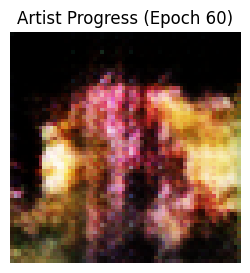

⭐ Epoch [61/100] | Police Loss: 0.6855 | Artist Loss: 2.8323
⭐ Epoch [62/100] | Police Loss: 0.5991 | Artist Loss: 3.2204
⭐ Epoch [63/100] | Police Loss: 0.5610 | Artist Loss: 3.1161
⭐ Epoch [64/100] | Police Loss: 0.6194 | Artist Loss: 3.0361
⭐ Epoch [65/100] | Police Loss: 0.6160 | Artist Loss: 3.4290
⭐ Epoch [66/100] | Police Loss: 0.6288 | Artist Loss: 3.2727
⭐ Epoch [67/100] | Police Loss: 0.5722 | Artist Loss: 3.1454
⭐ Epoch [68/100] | Police Loss: 0.6309 | Artist Loss: 3.0248
⭐ Epoch [69/100] | Police Loss: 0.6855 | Artist Loss: 3.0063
⭐ Epoch [70/100] | Police Loss: 0.6582 | Artist Loss: 2.8237
💾 Epoch 70 par Artist aur Police ka dimag save ho raha hai...


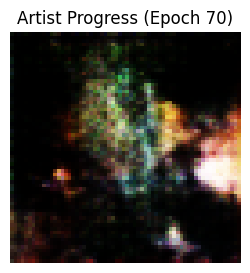

⭐ Epoch [71/100] | Police Loss: 0.6270 | Artist Loss: 2.9949
⭐ Epoch [72/100] | Police Loss: 0.6314 | Artist Loss: 3.0351
⭐ Epoch [73/100] | Police Loss: 0.6249 | Artist Loss: 2.8655
⭐ Epoch [74/100] | Police Loss: 0.6247 | Artist Loss: 2.8397
⭐ Epoch [75/100] | Police Loss: 0.6313 | Artist Loss: 2.9120
⭐ Epoch [76/100] | Police Loss: 0.6399 | Artist Loss: 2.8352
⭐ Epoch [77/100] | Police Loss: 0.6542 | Artist Loss: 2.8713
⭐ Epoch [78/100] | Police Loss: 0.6368 | Artist Loss: 2.7618
⭐ Epoch [79/100] | Police Loss: 0.6337 | Artist Loss: 2.9562
⭐ Epoch [80/100] | Police Loss: 0.6470 | Artist Loss: 2.8664
💾 Epoch 80 par Artist aur Police ka dimag save ho raha hai...


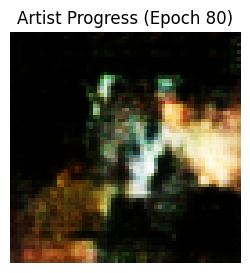

⭐ Epoch [81/100] | Police Loss: 0.6257 | Artist Loss: 2.8041
⭐ Epoch [82/100] | Police Loss: 0.6063 | Artist Loss: 2.7681
⭐ Epoch [83/100] | Police Loss: 0.6355 | Artist Loss: 2.8654
⭐ Epoch [84/100] | Police Loss: 0.6086 | Artist Loss: 2.9660
⭐ Epoch [85/100] | Police Loss: 0.6040 | Artist Loss: 2.8817
⭐ Epoch [86/100] | Police Loss: 0.5608 | Artist Loss: 3.0355
⭐ Epoch [87/100] | Police Loss: 0.5821 | Artist Loss: 2.9435
⭐ Epoch [88/100] | Police Loss: 0.5487 | Artist Loss: 2.9105
⭐ Epoch [89/100] | Police Loss: 0.5639 | Artist Loss: 2.8713
⭐ Epoch [90/100] | Police Loss: 0.5557 | Artist Loss: 2.9474
💾 Epoch 90 par Artist aur Police ka dimag save ho raha hai...


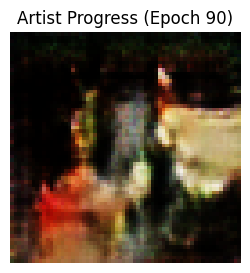

⭐ Epoch [91/100] | Police Loss: 0.5643 | Artist Loss: 2.9770
⭐ Epoch [92/100] | Police Loss: 0.5659 | Artist Loss: 2.9702
⭐ Epoch [93/100] | Police Loss: 0.5196 | Artist Loss: 3.1493
⭐ Epoch [94/100] | Police Loss: 0.4930 | Artist Loss: 3.0336
⭐ Epoch [95/100] | Police Loss: 0.5250 | Artist Loss: 3.1558
⭐ Epoch [96/100] | Police Loss: 0.5088 | Artist Loss: 3.2148
⭐ Epoch [97/100] | Police Loss: 0.5489 | Artist Loss: 3.2002
⭐ Epoch [98/100] | Police Loss: 0.4729 | Artist Loss: 3.0788
⭐ Epoch [99/100] | Police Loss: 0.5677 | Artist Loss: 3.4643
⭐ Epoch [100/100] | Police Loss: 0.4885 | Artist Loss: 3.3227
💾 Epoch 100 par Artist aur Police ka dimag save ho raha hai...


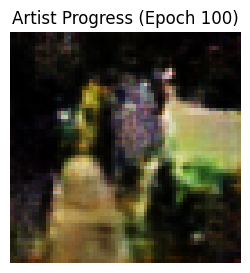


🎉 Maha-Training Complete! Models successfully save ho gaye hain.


In [15]:
import matplotlib.pyplot as plt
import os

# 1. Models save karne ke liye ek folder banate hain
os.makedirs('saved_models', exist_ok=True)

epochs = 100 # Lamba Yuddh! 100 rounds
print(f"🔥 Asli Yuddh Shuru! {epochs} Epochs ki training (Save feature ke sath)...\n")

# Hum ek 'Fixed Inspiration' lenge taaki dekh sakein ki ek hi idea par Artist kaise improve hota hai
fixed_noise = torch.randn(1, noise_dim).to(device)

for epoch in range(epochs):
    gen_loss_total = 0
    disc_loss_total = 0
    
    for i, real_images in enumerate(real_dataloader):
        batch_size = real_images.size(0)
        real_images = real_images.to(device)
        
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # -----------------------------------------------------
        # Police (Discriminator) Training
        # -----------------------------------------------------
        optimizer_pro_discriminator.zero_grad()
        outputs_real = my_pro_police(real_images)
        loss_real = criterion(outputs_real, real_labels)
        
        noise = torch.randn(batch_size, noise_dim).to(device)
        fake_images = my_pro_artist(noise)
        
        outputs_fake = my_pro_police(fake_images.detach())
        loss_fake = criterion(outputs_fake, fake_labels)
        
        loss_disc = loss_real + loss_fake
        loss_disc.backward()
        optimizer_pro_discriminator.step()
        
        # -----------------------------------------------------
        # Artist (Generator) Training
        # -----------------------------------------------------
        optimizer_pro_generator.zero_grad()
        outputs = my_pro_police(fake_images)
        loss_gen = criterion(outputs, real_labels) 
        
        loss_gen.backward()
        optimizer_pro_generator.step()

        gen_loss_total += loss_gen.item()
        disc_loss_total += loss_disc.item()
        
    print(f"⭐ Epoch [{epoch+1}/{epochs}] | Police Loss: {disc_loss_total/len(real_dataloader):.4f} | Artist Loss: {gen_loss_total/len(real_dataloader):.4f}")
    
    # -----------------------------------------------------
    # Har 10 Epochs ke baad Save aur Print karna
    # -----------------------------------------------------
    if (epoch + 1) % 10 == 0:
        print(f"💾 Epoch {epoch+1} par Artist aur Police ka dimag save ho raha hai...")
        torch.save(my_pro_artist.state_dict(), f"saved_models/artist_epoch_{epoch+1}.pth")
        torch.save(my_pro_police.state_dict(), f"saved_models/police_epoch_{epoch+1}.pth")
        
        # Progress ki ek photo nikal kar dikhana
        my_pro_artist.eval()
        with torch.no_grad():
            progress_photo = my_pro_artist(fixed_noise).detach().cpu().squeeze(0).permute(1, 2, 0)
            progress_photo = (progress_photo + 1) / 2
            
            plt.figure(figsize=(3, 3))
            plt.imshow(progress_photo.numpy())
            plt.title(f"Artist Progress (Epoch {epoch+1})")
            plt.axis("off")
            plt.show()
        my_pro_artist.train() # Wapas training mode me dalna

print("\n🎉 Maha-Training Complete! Models successfully save ho gaye hain.")

🎨 Final Exhibition: Pro Artist ki 16 Nayi Photos ki Gallery!



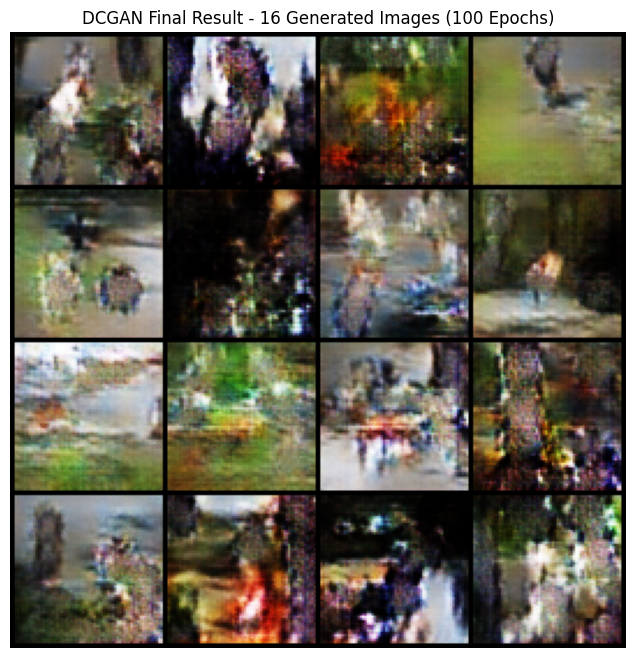

In [16]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils

print("🎨 Final Exhibition: Pro Artist ki 16 Nayi Photos ki Gallery!\n")

# 1. Artist ko Test mode me daalna
my_pro_artist.eval()
with torch.no_grad():
    # 16 alag-alag random ideas (noise) banana
    gallery_noise = torch.randn(16, noise_dim).to(device)
    # Pro Artist se ek sath 16 photos banwana
    gallery_photos = my_pro_artist(gallery_noise)

# 2. PyTorch ke in-built tool se 4x4 ka grid (frame) banana
# normalize=True khud hi -1 se 1 ko 0 se 1 me adjust kar dega
grid = vutils.make_grid(gallery_photos, nrow=4, padding=2, normalize=True)

# 3. GPU se CPU me lana aur shape theek karna
grid_to_show = grid.detach().cpu().permute(1, 2, 0)

# 4. Final Gallery Screen par dikhana
plt.figure(figsize=(8, 8))
plt.imshow(grid_to_show.numpy())
plt.title("DCGAN Final Result - 16 Generated Images (100 Epochs)")
plt.axis("off")
plt.show()

In [17]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# 1. Pro Data Transforms (Random Flip add kiya hai taaki AI zyada seekhe)
gan_transform_pro = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5), # 50% chance photo ko palatne ka
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) 
])

# 2. Bina kisi limit ke Full Dataset load karna
class FullPhotosDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        # LIMIT HATA DI GAYI HAI: Ab saari .jpg photos use hongi!
        self.img_names = [f for f in os.listdir(img_dir) if f.lower().endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image

# Dataset aur DataLoader ko wapas initialize karna
full_dataset = FullPhotosDataset(images_dir, transform=gan_transform_pro)
full_dataloader = DataLoader(full_dataset, batch_size=64, shuffle=True) 

print(f"🔥 Hardcore Mode ON: Total {len(full_dataset)} photos aur unke flipped versions load ho gaye!")

🔥 Hardcore Mode ON: Total 8091 photos aur unke flipped versions load ho gaye!


⚡ 500 Epochs ki Hardcore Training shuru ho rahi hai...

⭐ Epoch [1/500] | Police Loss: 1.0045 | Artist Loss: 3.0848
⭐ Epoch [2/500] | Police Loss: 0.7568 | Artist Loss: 2.7883
⭐ Epoch [3/500] | Police Loss: 0.6964 | Artist Loss: 2.7023
⭐ Epoch [4/500] | Police Loss: 1.2096 | Artist Loss: 2.6436
⭐ Epoch [5/500] | Police Loss: 0.6825 | Artist Loss: 2.7215
⭐ Epoch [6/500] | Police Loss: 0.6367 | Artist Loss: 2.7337
⭐ Epoch [7/500] | Police Loss: 0.6577 | Artist Loss: 2.8656
⭐ Epoch [8/500] | Police Loss: 0.6415 | Artist Loss: 2.7307
⭐ Epoch [9/500] | Police Loss: 0.6146 | Artist Loss: 2.7478
⭐ Epoch [10/500] | Police Loss: 0.6243 | Artist Loss: 2.7270
⭐ Epoch [11/500] | Police Loss: 0.7008 | Artist Loss: 2.8792
⭐ Epoch [12/500] | Police Loss: 0.6333 | Artist Loss: 2.6881
⭐ Epoch [13/500] | Police Loss: 0.6170 | Artist Loss: 2.6812
⭐ Epoch [14/500] | Police Loss: 0.6505 | Artist Loss: 2.7470
⭐ Epoch [15/500] | Police Loss: 0.6593 | Artist Loss: 2.7722
⭐ Epoch [16/500] | Police Loss: 0.6228

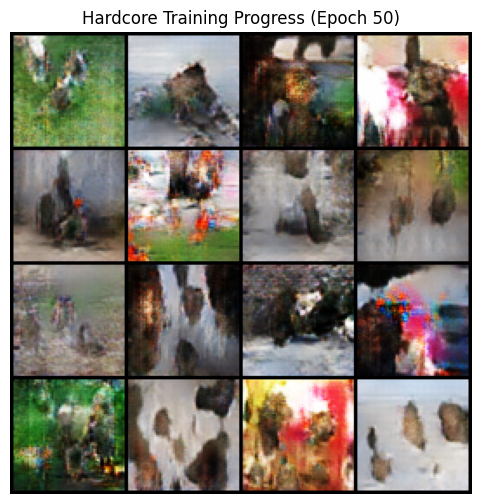

⭐ Epoch [51/500] | Police Loss: 0.1812 | Artist Loss: 4.9816
⭐ Epoch [52/500] | Police Loss: 0.2223 | Artist Loss: 4.5993
⭐ Epoch [53/500] | Police Loss: 0.4749 | Artist Loss: 4.5183
⭐ Epoch [54/500] | Police Loss: 0.2797 | Artist Loss: 4.2338
⭐ Epoch [55/500] | Police Loss: 0.3188 | Artist Loss: 4.2192
⭐ Epoch [56/500] | Police Loss: 0.3224 | Artist Loss: 4.1278
⭐ Epoch [57/500] | Police Loss: 0.4022 | Artist Loss: 4.1919
⭐ Epoch [58/500] | Police Loss: 0.3263 | Artist Loss: 4.1612
⭐ Epoch [59/500] | Police Loss: 0.3787 | Artist Loss: 4.2080
⭐ Epoch [60/500] | Police Loss: 0.8488 | Artist Loss: 4.1971
⭐ Epoch [61/500] | Police Loss: 0.4120 | Artist Loss: 3.9232
⭐ Epoch [62/500] | Police Loss: 0.3204 | Artist Loss: 3.9138
⭐ Epoch [63/500] | Police Loss: 0.3190 | Artist Loss: 3.8540
⭐ Epoch [64/500] | Police Loss: 0.3583 | Artist Loss: 3.9195
⭐ Epoch [65/500] | Police Loss: 0.3449 | Artist Loss: 3.9612
⭐ Epoch [66/500] | Police Loss: 0.3349 | Artist Loss: 4.0386
⭐ Epoch [67/500] | Polic

In [ ]:
import matplotlib.pyplot as plt

epochs = 500 # Ultra Hardcore Training!
print(f"⚡ {epochs} Epochs ki Hardcore Training shuru ho rahi hai...\n")

# Same fixed noise taaki ek hi image ko clear hote hue dekh sakein
fixed_noise = torch.randn(16, noise_dim).to(device)

for epoch in range(epochs):
    gen_loss_total = 0
    disc_loss_total = 0
    
    for i, real_images in enumerate(full_dataloader):
        batch_size = real_images.size(0)
        real_images = real_images.to(device)
        
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # -----------------------------------------------------
        # Police (Discriminator) Training
        # -----------------------------------------------------
        optimizer_pro_discriminator.zero_grad()
        
        outputs_real = my_pro_police(real_images)
        loss_real = criterion(outputs_real, real_labels)
        
        noise = torch.randn(batch_size, noise_dim).to(device)
        fake_images = my_pro_artist(noise)
        
        outputs_fake = my_pro_police(fake_images.detach())
        loss_fake = criterion(outputs_fake, fake_labels)
        
        loss_disc = loss_real + loss_fake
        loss_disc.backward()
        optimizer_pro_discriminator.step()
        
        # -----------------------------------------------------
        # Artist (Generator) Training
        # -----------------------------------------------------
        optimizer_pro_generator.zero_grad()
        outputs = my_pro_police(fake_images)
        loss_gen = criterion(outputs, real_labels) 
        
        loss_gen.backward()
        optimizer_pro_generator.step()

        gen_loss_total += loss_gen.item()
        disc_loss_total += loss_disc.item()
        
    # Har epoch ka result print karna
    print(f"⭐ Epoch [{epoch+1}/{epochs}] | Police Loss: {disc_loss_total/len(full_dataloader):.4f} | Artist Loss: {gen_loss_total/len(full_dataloader):.4f}")
    
    # -----------------------------------------------------
    # Har 50 Epochs ke baad Model Save aur Gallery Print
    # -----------------------------------------------------
    if (epoch + 1) % 50 == 0:
        print(f"\n💾 [Epoch {epoch+1}] Checkpoint Save ho raha hai...")
        torch.save(my_pro_artist.state_dict(), f"saved_models/artist_hardcore_epoch_{epoch+1}.pth")
        
        my_pro_artist.eval()
        with torch.no_grad():
            gallery_photos = my_pro_artist(fixed_noise)
            grid = vutils.make_grid(gallery_photos, nrow=4, padding=2, normalize=True)
            grid_to_show = grid.detach().cpu().permute(1, 2, 0)
            
            plt.figure(figsize=(6, 6))
            plt.imshow(grid_to_show.numpy())
            plt.title(f"Hardcore Training Progress (Epoch {epoch+1})")
            plt.axis("off")
            plt.show()
        my_pro_artist.train()

print("\n🏆 INCREDIBLE! 500 Epochs ki hardcore training complete ho chuki hai.")

In [ ]:
import torch.optim as optim
import torch.nn as nn
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import gc # Garbage Collector (Memory saaf karne ke liye)

# Naye sire se dono AI ko zinda karna aur Optimizers set karna
my_pro_artist = DCGAN_Generator(noise_dim).to(device)
my_pro_police = DCGAN_Discriminator().to(device)
criterion = nn.BCELoss()
optimizer_pro_generator = optim.Adam(my_pro_artist.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_pro_discriminator = optim.Adam(my_pro_police.parameters(), lr=0.0002, betas=(0.5, 0.999))

epochs = 500 
print(f"⚡ Crash-Proof Hardcore Training Shuru ({epochs} Epochs)...\n")

fixed_noise = torch.randn(16, noise_dim).to(device)

for epoch in range(epochs):
    gen_loss_total = 0
    disc_loss_total = 0
    
    for i, real_images in enumerate(full_dataloader):
        batch_size = real_images.size(0)
        real_images = real_images.to(device)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # --- Police Training ---
        optimizer_pro_discriminator.zero_grad()
        outputs_real = my_pro_police(real_images)
        loss_real = criterion(outputs_real, real_labels)
        
        noise = torch.randn(batch_size, noise_dim).to(device)
        fake_images = my_pro_artist(noise)
        outputs_fake = my_pro_police(fake_images.detach())
        loss_fake = criterion(outputs_fake, fake_labels)
        
        loss_disc = loss_real + loss_fake
        loss_disc.backward()
        optimizer_pro_discriminator.step()
        
        # --- Artist Training ---
        optimizer_pro_generator.zero_grad()
        outputs = my_pro_police(fake_images)
        loss_gen = criterion(outputs, real_labels) 
        
        loss_gen.backward()
        optimizer_pro_generator.step()

        gen_loss_total += loss_gen.item()
        disc_loss_total += loss_disc.item()
        
        # 🧹 MEMORY SWEEPER (Anti-Crash Trick)
        # Har batch ke baad variables ko memory se hatana aur cache clear karna
        del real_images, noise, fake_images, outputs_real, outputs_fake, loss_real, loss_fake
        if i % 50 == 0:
            torch.cuda.empty_cache()
            gc.collect()

    print(f"⭐ Epoch [{epoch+1}/{epochs}] | Police: {disc_loss_total/len(full_dataloader):.4f} | Artist: {gen_loss_total/len(full_dataloader):.4f}")
    
    # Har 50 Epochs ke baad Save aur Print
    if (epoch + 1) % 50 == 0:
        print(f"\n💾 Checkpoint Save ho raha hai...")
        # Is baar dono ka dimag save ho raha hai!
        torch.save(my_pro_artist.state_dict(), f"saved_models/artist_hardcore_{epoch+1}.pth")
        torch.save(my_pro_police.state_dict(), f"saved_models/police_hardcore_{epoch+1}.pth")
        
        my_pro_artist.eval()
        with torch.no_grad():
            gallery_photos = my_pro_artist(fixed_noise)
            grid = vutils.make_grid(gallery_photos, nrow=4, padding=2, normalize=True)
            plt.figure(figsize=(6, 6))
            plt.imshow(grid.detach().cpu().permute(1, 2, 0).numpy())
            plt.title(f"Crash-Proof Training Progress (Epoch {epoch+1})")
            plt.axis("off")
            plt.show()
        my_pro_artist.train()

print("\n🏆 INCREDIBLE! Crash-proof training complete ho chuki hai.")